### Clustering Customer Segmentation with K-means

### Step 0: Import the libraries needed

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ETSU_NAVY = '#00053E'
ETSU_GOLD = '#FFC72C'

print("Ready")



Ready


### Step 1: Load and explore

In [9]:
df = pd.read_csv("Mall_Customers.csv")
print("Shape:", df.shape)
df.head()

Shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [11]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


### Step 2: Pick Features and scale

In [19]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].values
X

scaler = StandardScaler()
Xs = scaler.fit_transform(X) # scaled features that k-means will actually use
print("Scaled means (~0):", np.round(Xs.mean(axis=0), 3), "std (~1):", np.round(Xs.std(axis=0), 3))
Xs

Scaled means (~0): [-0. -0.] std (~1): [1. 1.]


array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002],
       [-1.58632148, -1.4053405 ],
       [-1.58632148,  1.89449216],
       [-1.54815205, -1.36651894],
       [-1.54815205,  1.04041783],
       [-1.54815205, -1.44416206],
       [-1.54815205,  1.11806095],
       [-1.50998262, -0.59008772],
       [-1.50998262,  0.61338066],
       [-1.43364376, -0.82301709],
       [-1.43364376,  1.8556706 ],
       [-1.39547433, -0.59008772],
       [-1.39547433,  0.88513158],
       [-1.3573049 , -1.75473454],
       [-1.3573049 ,  0.88513158],
       [-1.24279661, -1.4053405 ],
       [-1.24279661,  1.23452563],
       [-1.24279661, -0.7065524 ],
       [-1.24279661,  0.41927286],
       [-1.20462718,

### Step 4: How many clusters?

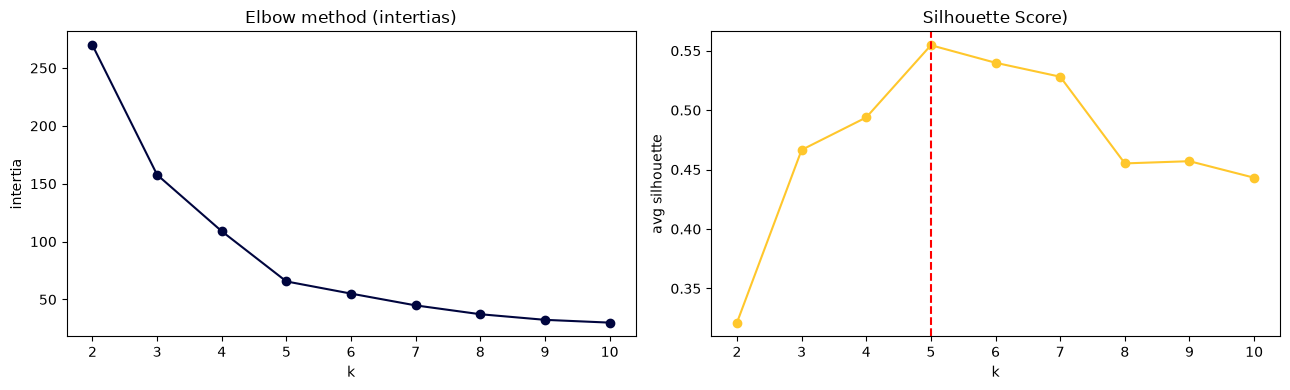

In [ ]:
# use the intertia and the elbow method
# intertia measures how tight the clusters are
# silhouette score for each point it compares the average distance to points in its own cluster againts the average distance to points in the nearest other cluster.

ks = range(2, 11)
intertias, sils = [], []

for k in ks:
  km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
  intertias.append(km.inertia_)
  sils.append(silhouette_score(Xs, km.labels_))

fig, ax = plt.subplots(1, 2, figsize =(13, 4))
ax[0].plot(list(ks), intertias, "o-", color=ETSU_NAVY)
ax[0].set_title("Elbow method (intertias)"); ax[0].set_xlabel("k"); ax[0].set_ylabel("intertia")

ax[1].plot(list(ks), sils, "o-", color=ETSU_GOLD)
ax[1].set_title("Silhouette Score)"); ax[1].set_xlabel("k"); ax[1].set_ylabel("avg silhouette")

# retrieving the best k (prints as red line)
best_k = list(ks)[int(np.argmax(sils))] # same as writing [2, 3, 4, 5][2] basically indexing the list

ax[1].axvline(best_k, color="red", linestyle="--")
plt.tight_layout(); plt.show()

In [27]:
print("silhouette by k:", {k : round(s, 3) for k, s in zip(ks, sils)}) # using dictionary comprehension to pair clusters and respecive sils

print("Best k by silhouette:", best_k)

silhouette by k: {2: 0.321, 3: 0.467, 4: 0.494, 5: 0.555, 6: 0.54, 7: 0.528, 8: 0.455, 9: 0.457, 10: 0.443}
Best k by silhouette: 5


### Step 5: Fit k-means with the chosen k

In [ ]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs) # run the k means to create clusters
df["cluster"] = kmeans.labels_  # attach each customers cluster id

df[["Annual Income (k$)", "Spending Score (1-100)", "cluster"]].head()

,Annual Income (k$),Spending Score (1-100),cluster
0,15,39,4
1,15,81,2
2,16,6,4
3,16,77,2
4,17,40,4


### Step 6: Visualize the segments

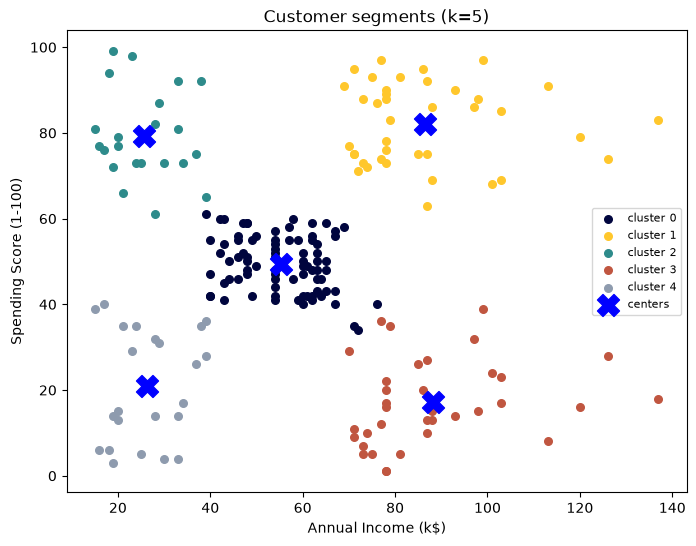

In [37]:
PALETTE = ["#00053E", "#FFC72C", "#2E8B8B", "#C05640", "#8E9BAE"]  # up to 5 clusters
plt.figure(figsize=(8, 6))
for c in range(k):
  m = df["cluster"] == c
  plt.scatter(df.loc[m, "Annual Income (k$)"], df.loc[m, "Spending Score (1-100)"], s=30, color=PALETTE[c], label=f"cluster {c}")

# cluster centers back in original units

centers = df.groupby("cluster")[features].mean()
plt.scatter(centers[features[0]], centers[features[1]], s=250, marker="X", color="blue", label="centers")

plt.xlabel("Annual Income (k$)");
plt.ylabel("Spending Score (1-100)")
plt.title('Customer segments (k=5)'); plt.legend(fontsize=8)
plt.show()

### Step 7: Profile and name the segments

**Very important.** Clusters are useless until you can say what each one *is* and
what to do about it. We summarize each cluster by its average income, average spending, and
size, then describe it in plain business language.

In [38]:
profile = df.groupby("cluster").agg(
    customers=("CustomerID", "count"),
    avg_income=("Annual Income (k$)", "mean"),
    avg_spending=("Spending Score (1-100)", "mean"),
).round(1)
profile

,customers,avg_income,avg_spending
cluster,,,
0,81,55.3,49.5
1,39,86.5,82.1
2,22,25.7,79.4
3,35,88.2,17.1
4,23,26.3,20.9
